# Estimate a discrete generic equivalent layer

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
from scipy.fft import fftfreq, fftshift

In [5]:
import time

In [6]:
import pickle

In [7]:
from gravmag import data_structures, utils, aux_vedo, transforms, inverse_distance, convolve, filters, constants, eqlayer
from gravmag.models import rectangular_prism as rp

In [8]:
import vedo

In [9]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Load data

In [10]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [11]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [12]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [13]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [14]:
mag_intensity = pickle.load(open('model/1_model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/1_model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/1_model_mag_dec.pickle', 'rb'))

In [15]:
print(mag_inc[0], mag_dec[0])

-10.2 -19.8


In [16]:
main_field = pickle.load(open('model/2_main_field.pickle', 'rb'))

In [17]:
print('Main field inc = {}° dec = {}°'.format(main_field['inc'], main_field['dec']))

Main field inc = -30° dec = 10°


In [18]:
simulated_fields = pickle.load(open('model/2_simulated_fields.pickle', 'rb'))

In [19]:
coordinates_grid = pickle.load(open('model/2_coordinates_grid.pickle', 'rb'))

In [20]:
print('Regular grid of coordinates on the horizontal plane {} m'.format(coordinates_grid['z']))

Regular grid of coordinates on the horizontal plane -150 m


In [21]:
dipole_layer = pickle.load(open('model/4a_dipole_layer.pickle', 'rb'))

### Get preliminary information from loaded data

In [22]:
# Cartesian components of the model magnetization
v_hat = utils.unit_vector(inc=mag_inc[0], dec=mag_dec[0])

In [23]:
# compute a normalized horizontal projection of v_hat to plot
v_hat_horizontal = v_hat[:2]/np.linalg.norm(v_hat[:2])

In [24]:
print('Synthetic source magnetization inc = {}° dec = {}°'.format(mag_inc[0], mag_dec[0]))

Synthetic source magnetization inc = -10.2° dec = -19.8°


In [25]:
# Grid spacing
dx, dy = data_structures.grid_xy_spacing(coordinates_grid['area'], coordinates_grid['shape'])

In [26]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

In [27]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [28]:
# Cartesian components of the dipoles forming the equivalent layers
h_inc=90
h_dec=0
h_hat = utils.unit_vector(inc=h_inc, dec=h_dec)

In [29]:
print('Layer magnetization inc = {}° dec = {}°'.format(h_inc, h_dec))

Layer magnetization inc = 90° dec = 0°


In [30]:
# compute a normalized horizontal projection of F_hat and h_hat to plot
F_hat_horizontal = F_hat[:2]/np.linalg.norm(F_hat[:2])
h_hat_horizontal = h_hat[:2]/np.linalg.norm(h_hat[:2])

### Compute the closed-form dipole layer by using the regularization parameter $\mu_{\varepsilon}$

In [31]:
# set a layer that crosses the sources
z_layer = 200

In [32]:
print('The distance from coordinates grid to layer is {} m'.format(z_layer-coordinates_grid['z']))

The distance from coordinates grid to layer is 350 m


In [33]:
# compute 2D Fourier transform of pseudogravity anomaly with padding
FT_pseudo_grav = transforms.DFT(
    data = data_structures.grid_xy_full_flatten_to_matrix(
        data = simulated_fields['gz'], grid_orientation='xy', shape=coordinates_grid['shape']
    ), 
    pad_mode='linear_ramp'
)

In [34]:
# compute wavenumbers
wavenumbers = data_structures.grid_wavenumbers(grid = coordinates_grid, pad = True)

In [35]:
print('Max/min wavenumbers along x: {:.5f}/{:.5f} | y: {:.5f}/{:.5f}'.format(
    np.min(wavenumbers['x']), np.max(wavenumbers['x']), np.min(wavenumbers['y']), np.max(wavenumbers['y'])
))

Max/min wavenumbers along x: -0.08586/0.08571 | y: -0.08613/0.08596


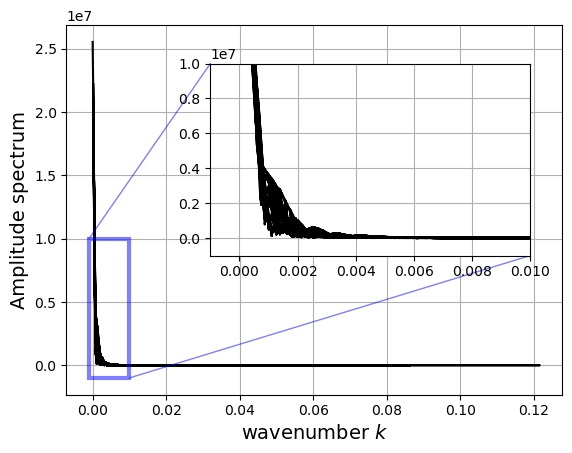

In [36]:
fig, ax = plt.subplots()

ax.plot(
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = wavenumbers['z'], grid_orientation = 'xy'
    ),
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = np.abs(FT_pseudo_grav), grid_orientation = 'xy'
    ),
    'k-'
)
ax.set_xlabel('wavenumber $k$', fontsize=14)
ax.set_ylabel('Amplitude spectrum', fontsize=14)
ax.grid()

# # inset axes
#inset = fig.add_axes([left, bottom, width, height])
inset = fig.add_axes([0.35, 0.4, 0.50, 0.40])

inset.plot(
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = wavenumbers['z'], grid_orientation = 'xy'
    ),
    data_structures.grid_xy_full_matrix_to_flatten(
        grid = np.abs(FT_pseudo_grav), grid_orientation = 'xy'
    ),
    'k-'
)

# # subregion of the original image
inset.set_xlim(-0.001, 0.01)
inset.set_ylim(-0.01e8, 0.1e8)
#inset.set_xticklabels([])
#inset.set_yticklabels([])
inset.grid()

ax.indicate_inset_zoom(inset, edgecolor="blue", linewidth=3)

plt.show()

In [37]:
# define the continuation filter
down_continuation_filter = filters.continuation(wavenumbers = wavenumbers, dz = z_layer-coordinates_grid['z'])

In [38]:
# define the regularization filter
regularization = 1 / (1 + (10*wavenumbers['z']*wavenumbers['z']*down_continuation_filter))

In [39]:
# define a directional derivative of first order along the true magnetization direction
mag_dir = filters.direction(wavenumbers = wavenumbers, inc = mag_inc[0], dec = mag_dec[0])

In [40]:
# define the composed dipole layer filter
wavenumbers['z'][0,0] = 1.
dipole_layer_filter = [mag_dir/wavenumbers['z'], down_continuation_filter, regularization]
wavenumbers['z'][0,0] = 0.

In [41]:
# theoretical dipole layer in the Fourier domain (unscaled)
FT_dipole_layer_reg = convolve.compute(FT_pseudo_grav, dipole_layer_filter)

In [42]:
# theoretical equivalent layer
dipole_layer_reg = ((dx*dy*constants.T2nanoT)/(2*np.pi*constants.T2microT))*transforms.IDFT(FT_dipole_layer_reg, unpad=True)

In [43]:
dipole_layer_reg = data_structures.grid_xy_full_matrix_to_flatten(
    grid=dipole_layer_reg,
    grid_orientation='xy'    
)

In [44]:
dipole_layer_reg.shape

(132000,)

In [45]:
dipole_layer.shape

(132000,)

In [46]:
diff = dipole_layer_reg - dipole_layer

### Compare with the estimated dipole layer

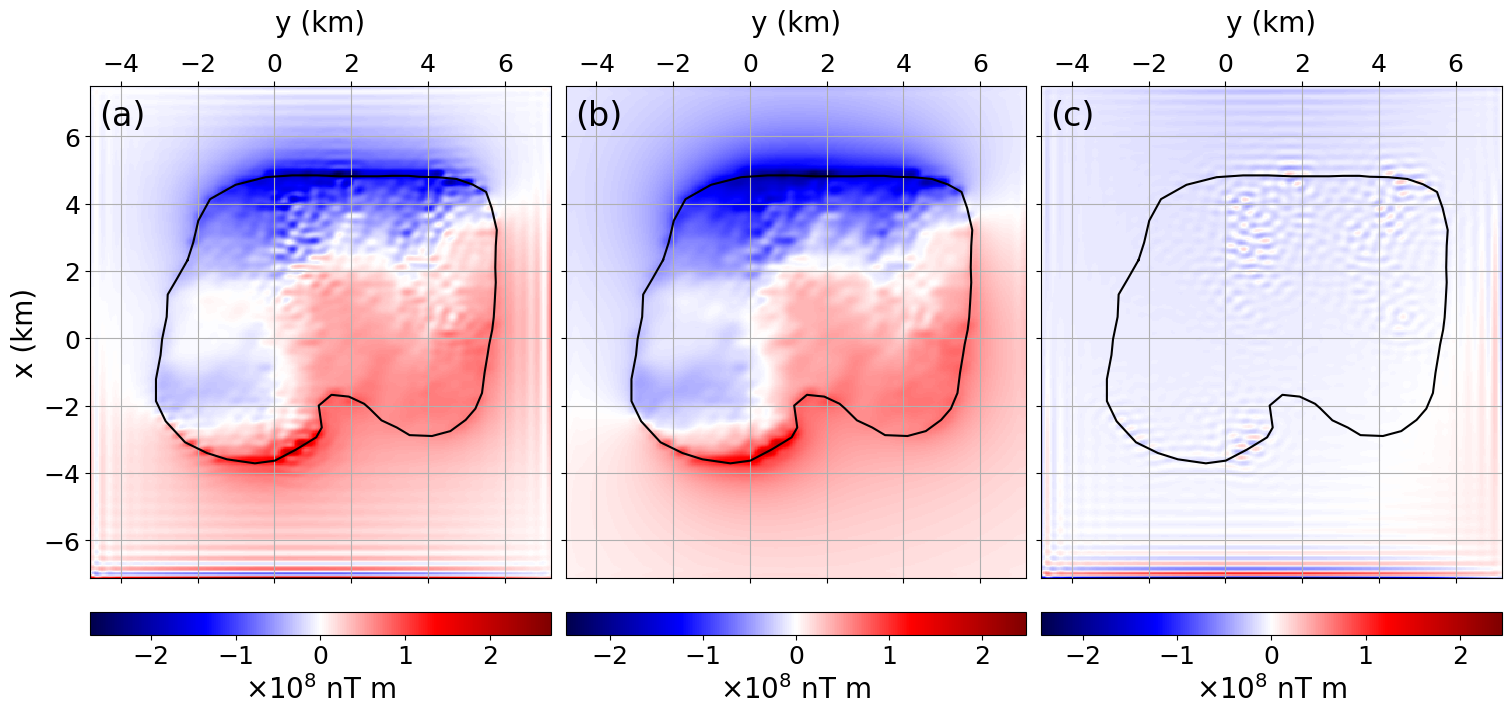

In [47]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,7)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)']

mosaic_elements = ['a', 'b', 'c']

units = 3*['$\\times 10^{8}$ nT m']


ranges = [
    np.max(np.abs(dipole_layer))*1e-8,
    np.max(np.abs(dipole_layer_reg))*1e-8,
    np.max(np.abs(diff)*1e-8)
]

for (element, layer, label, ranges_layer, unit) in zip(
    mosaic_elements, 
    [1e-8*dipole_layer, 1e-8*dipole_layer_reg, 1e-8*diff], 
    labels,
    ranges,
    units,
):
    ax = mosaic[element]
    #ax.axis('scaled')
    im = ax.pcolormesh(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=layer,
            grid_orientation='xy',
            shape=coordinates_grid['shape']
        ),
        cmap='seismic', vmin=-ranges_layer, vmax=ranges_layer
    )
    cb = fig.colorbar(
        im, 
        ax=ax, 
        location='bottom',
    )
    cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
    cb.ax.set_xlabel(unit, fontsize=20, loc='center')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)
    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=20)
for element in ['a','b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=True, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')

plt.show()

### Compute the data fit

In [48]:
# compute the SEDM
R2 = inverse_distance.sedm_BTTB(
    data_grid = coordinates_grid, 
    delta_z = z_layer - coordinates_grid['z'],
    grid_orientation = 'xy'
)

In [49]:
# compute the tensor components (second derivatives) of the inverse distance function
Tensor = inverse_distance.grad_tensor_BTTB(
    data_grid = coordinates_grid,
    delta_z = z_layer - coordinates_grid['z'],
    SEDM = R2,
    grid_orientation = 'xy',
    components=['xx', 'xy', 'xz', 'yy', 'yz', 'zz']
)

In [50]:
# compute the eigenvalues matrices associated to second derivatives of inverse distance function
L_Tensor = dict()
for component in ['xx', 'xy', 'xz', 'yy', 'yz', 'zz']:
    L_Tensor[component] = convolve.eigenvalues_BCCB(BTTB_metadata=Tensor[component])

In [51]:
# directional factor to compute the approximated total-field anomaly
a = utils.directional_factors(t=h_hat, u=F_hat)

In [52]:
# Compute the resultant eigenvalues matrix associated with the directional derivative of second order
L = np.zeros_like(L_Tensor['xx'])
for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
    L += a[component]*L_Tensor[component]

In [53]:
# list for storing the predicted magnetic field components
predicted_fields = dict()

In [54]:
# magnetic induction field component x
result = np.zeros_like(simulated_fields['bx'])

for h_component, component in zip(h_hat, ['xx', 'xy', 'xz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = dipole_layer_reg
    )

predicted_fields['bx'] = result # convert to nT

# magnetic induction field component y
result = np.zeros_like(simulated_fields['by'])

for h_component, component in zip(h_hat, ['xy', 'yy', 'yz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = dipole_layer_reg
    )

predicted_fields['by'] = result # convert to nT

# magnetic induction field component z
result = np.zeros_like(simulated_fields['bz'])

for h_component, component in zip(h_hat, ['xz', 'yz', 'zz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = dipole_layer_reg
    )

predicted_fields['bz'] = result # convert to nT

In [55]:
# amplitude of anomalous B field
predicted_fields['b'] = np.sqrt(
    predicted_fields['bx']**2 + 
    predicted_fields['by']**2 + 
    predicted_fields['bz']**2
)

In [56]:
# reduction to the pole
result = np.zeros_like(simulated_fields['bx'])

result = convolve.product_BCCB_vector(
    eigenvalues = L_Tensor['zz'],
    ordering = 'row',
    v = dipole_layer_reg
)

FT_result = transforms.DFT(
    data=data_structures.grid_xy_full_flatten_to_matrix(
        data=result,
        grid_orientation='xy',
        shape=coordinates_grid['shape']
    ), 
    pad_mode='linear_ramp'
)

wavenumbers = data_structures.grid_wavenumbers(
    grid=coordinates_grid,
    pad=True
)

Av = filters.direction(
    wavenumbers=wavenumbers,
    inc=mag_inc[0],
    dec=mag_dec[0]
)
Av[0,0]=1.

FT_result *= wavenumbers['z'] / Av

result = transforms.IDFT(FT_data=FT_result, unpad=True)

predicted_fields['rtp'] = data_structures.grid_xy_full_matrix_to_flatten(
    grid=result,
    grid_orientation='xy'
)

In [57]:
# approximated total-field anomaly
result = np.zeros_like(simulated_fields['bx'])

for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
    result[:] += convolve.product_BCCB_vector(
        eigenvalues = a[component]*L_Tensor[component],
        ordering = 'row',
        v = dipole_layer_reg
    )

predicted_fields['atfa'] = result # convert to nT

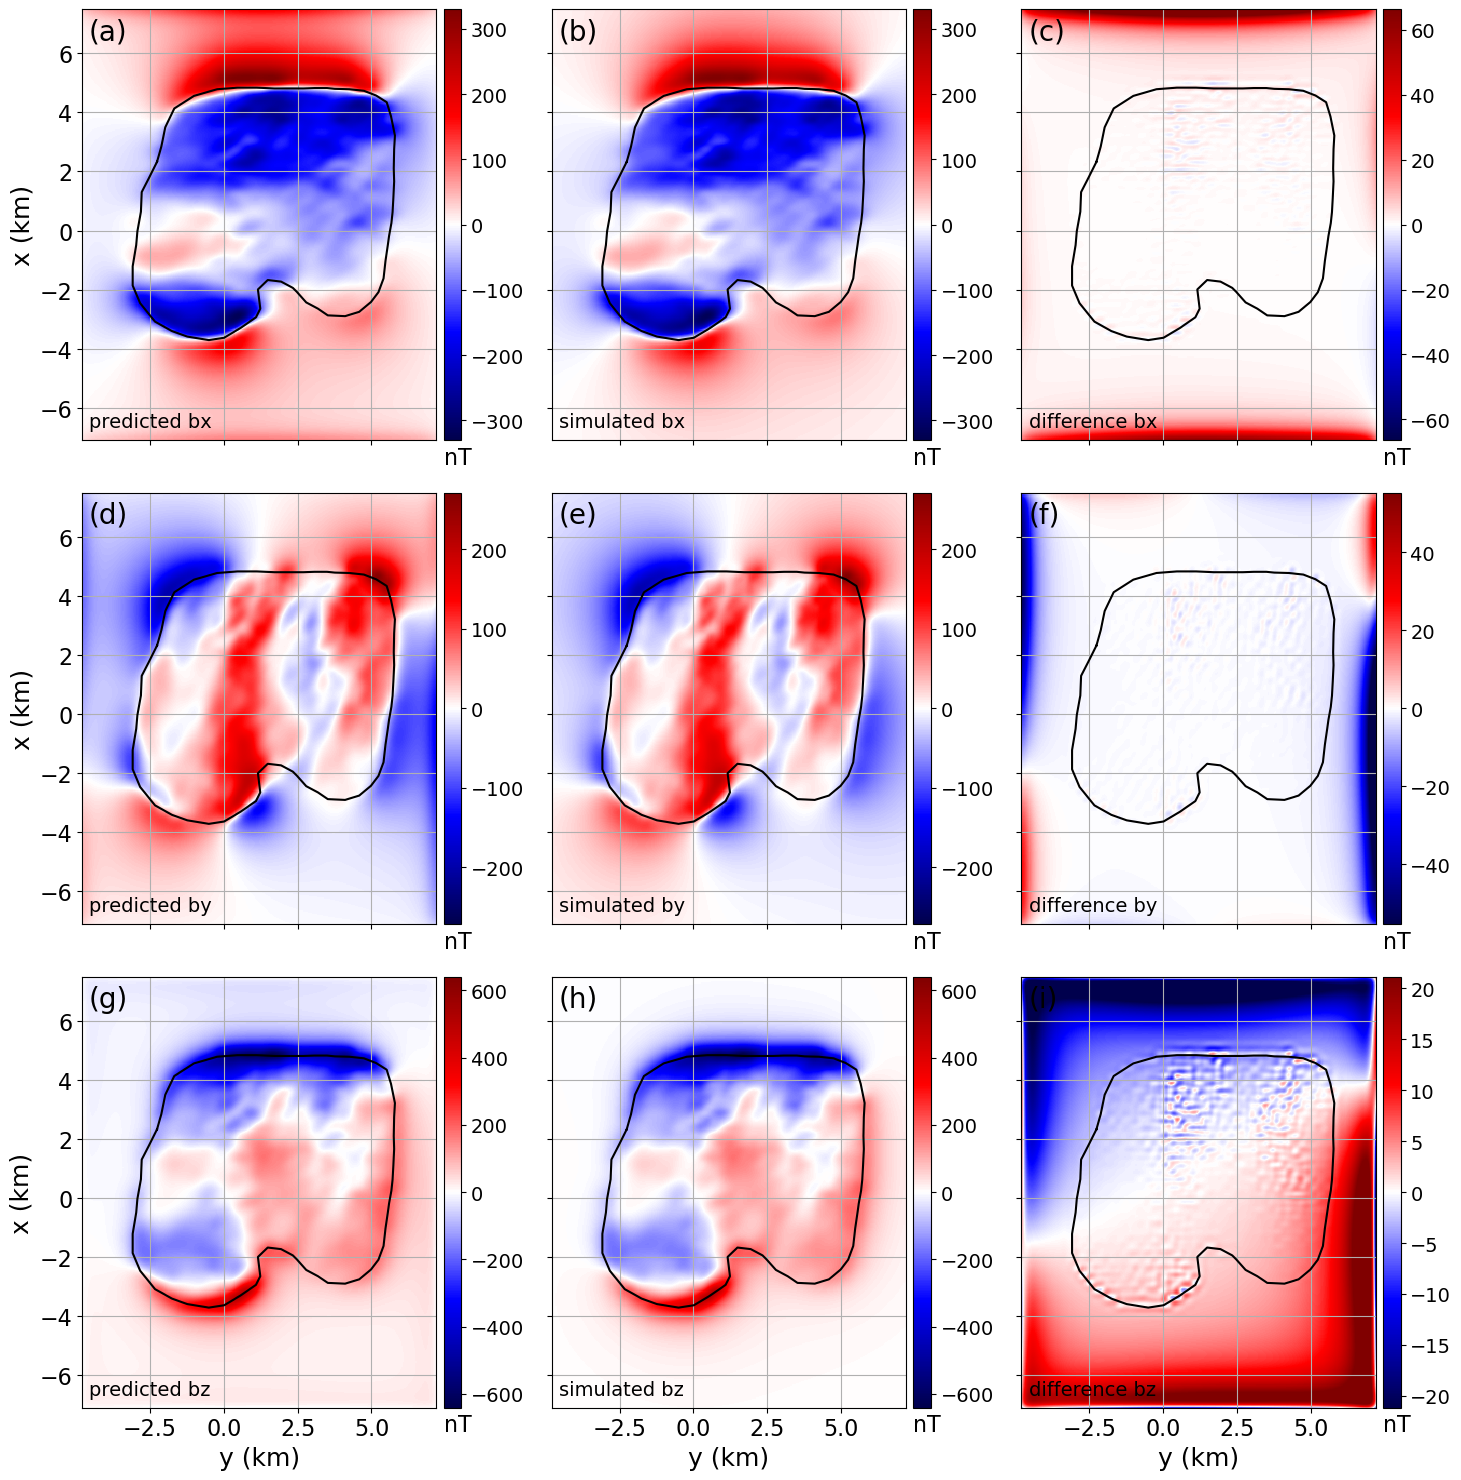

In [58]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)'], ['(d)', '(e)', '(f)'], ['(g)', '(h)', '(i)']]

mosaic_elements = [['a', 'b', 'c'], ['d', 'e', 'f'], ['g', 'h', 'i']]

for (mosaic_row, field, labels_row) in zip(
    mosaic_elements, 
    ['bx', 'by', 'bz'],
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [0.6*np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                grid_orientation='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)
        # ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='purple') 
        # ax.arrow(x=6, y=5.2, dx=h_hat_horizontal[1], dy=h_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, color='black')

    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h', 'i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)

plt.show()

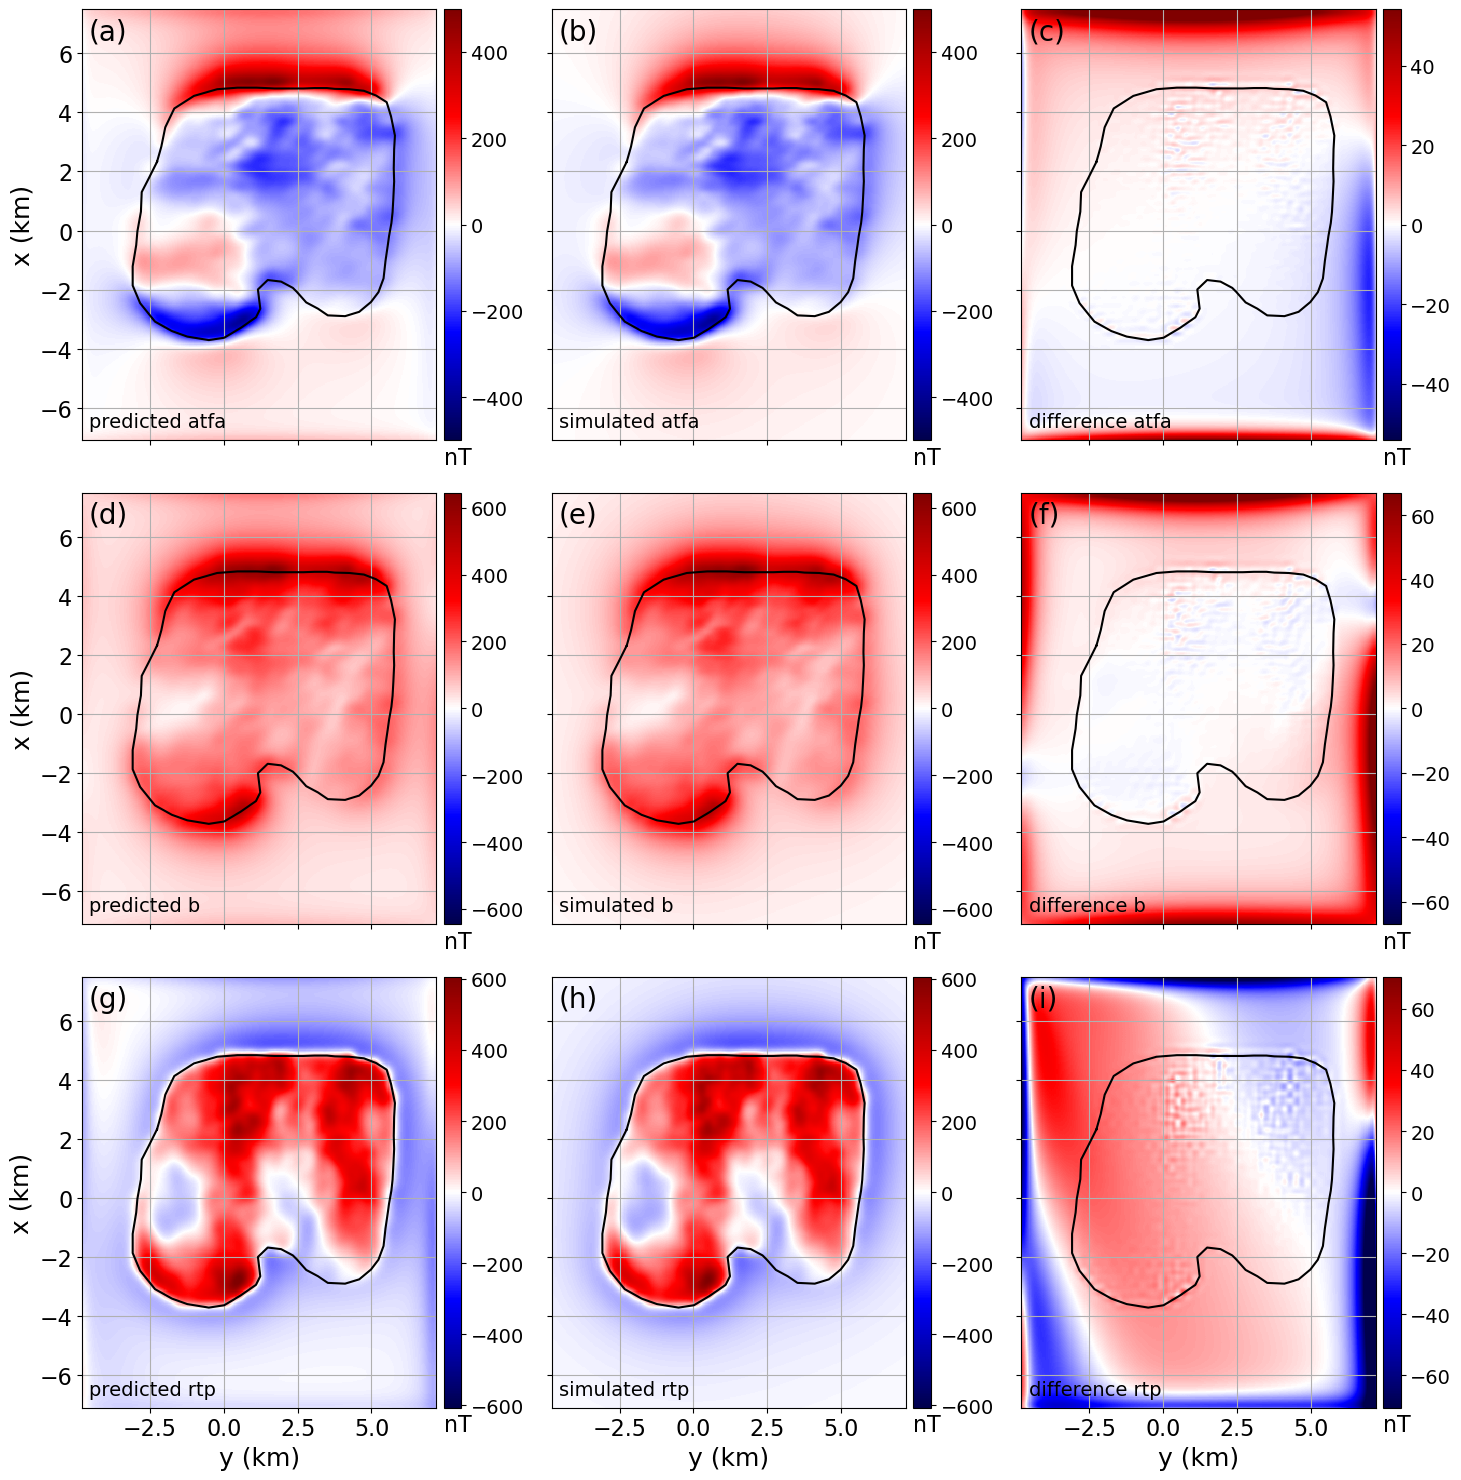

In [59]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)'], ['(d)', '(e)', '(f)'], ['(g)', '(h)', '(i)']]

mosaic_elements = [['a', 'b', 'c'], ['d', 'e', 'f'], ['g', 'h', 'i']]

for (mosaic_row, field, labels_row) in zip(
    mosaic_elements, 
    ['atfa', 'b', 'rtp'],
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [0.6*np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                grid_orientation='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)
        # ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='purple') 
        # ax.arrow(x=6, y=5.2, dx=h_hat_horizontal[1], dy=h_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, color='black')
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h', 'i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)
    
plt.show()

### Save the estimated dipole layer and its predicted potential fields

In [60]:
pickle.dump(dipole_layer_reg, open('model/4c_dipole_layer_reg.pickle', 'wb'))

In [61]:
pickle.dump(predicted_fields, open('model/4c_dipole_reg_predicted_fields.pickle', 'wb'))